<a href="https://colab.research.google.com/github/Dedeepya0510/CSA4703---Deep-Learning/blob/main/Lab%20Experiment/Exp_11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Epoch 1/5
36/36 ━━━━━━━━━━━━━━━━━━━━ 8s 143ms/step - accuracy: 0.5962 - loss: 1.5275 - val_accuracy: 0.8368 - val_loss: 0.5227
Epoch 2/5
36/36 ━━━━━━━━━━━━━━━━━━━━ 5s 130ms/step - accuracy: 0.8712 - loss: 0.3883 - val_accuracy: 0.9549 - val_loss: 0.1754
Epoch 3/5
36/36 ━━━━━━━━━━━━━━━━━━━━ 4s 106ms/step - accuracy: 0.9391 - loss: 0.1994 - val_accuracy: 0.9549 - val_loss: 0.1582
Epoch 4/5
36/36 ━━━━━━━━━━━━━━━━━━━━ 4s 97ms/step - accuracy: 0.9591 - loss: 0.1344 - val_accuracy: 0.9514 - val_loss: 0.1278
Epoch 5/5
36/36 ━━━━━━━━━━━━━━━━━━━━ 5s 134ms/step - accuracy: 0.9765 - loss: 0.0846 - val_accuracy: 0.9653 - val_loss: 0.0957
Test Accuracy: 0.9694444537162781


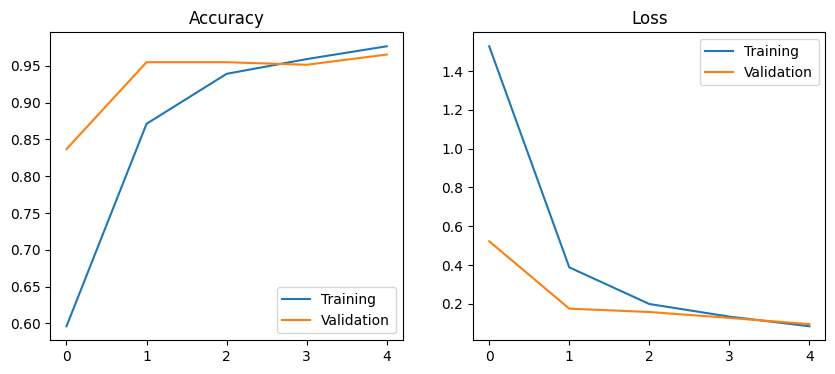

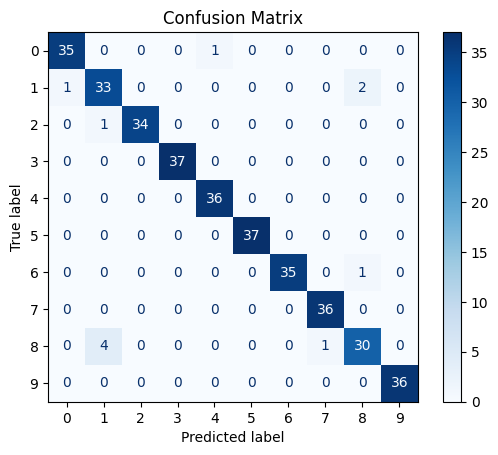

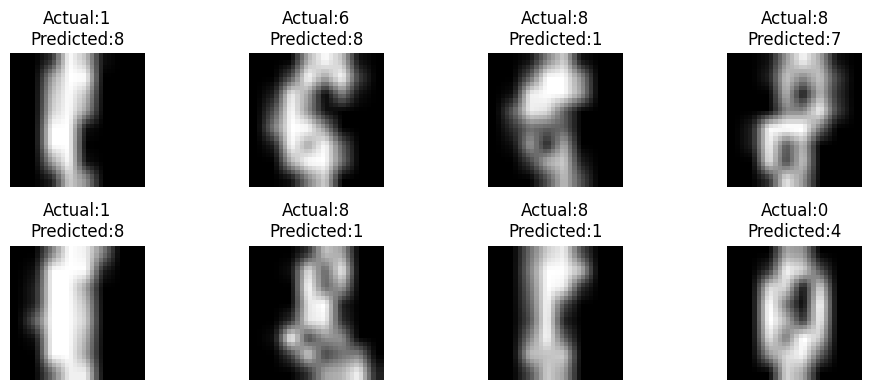

AttributeError: The layer sequential_2 has never been called and thus has no defined input.

In [4]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Load small built-in dataset
digits = load_digits()
X = digits.images[..., np.newaxis]
y = digits.target

# Resize and normalize
X = tf.image.resize(X, (32, 32)).numpy() / 16.0

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.2,
    random_state=42, stratify=y_train
)

# Build CNN
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 1)),
    tf.keras.layers.Conv2D(16, 3, activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(32, 3, activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(
    X_train, y_train, epochs=5, batch_size=32,
    validation_data=(X_val, y_val), verbose=1
)

print("Test Accuracy:", model.evaluate(X_test, y_test, verbose=0)[1])

# Accuracy and loss graphs
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training')
plt.plot(history.history['val_loss'], label='Validation')
plt.title("Loss")
plt.legend()
plt.show()

# Confusion matrix
pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
ConfusionMatrixDisplay(confusion_matrix(y_test, pred)).plot(cmap='Blues')
plt.title("Confusion Matrix")
plt.show()

# Misclassified images
wrong = np.where(pred != y_test)[0]
plt.figure(figsize=(10, 4))
for i, index in enumerate(wrong[:8]):
    plt.subplot(2, 4, i + 1)
    plt.imshow(X_test[index].squeeze(), cmap='gray')
    plt.title(f"Actual:{y_test[index]}\nPredicted:{pred[index]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

# First convolution feature maps
feature_model = tf.keras.Model(model.input, model.layers[0].output)
features = feature_model.predict(X_test[:1], verbose=0)

plt.figure(figsize=(8, 4))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(features[0, :, :, i], cmap='viridis')
    plt.axis('off')
plt.suptitle("First Convolution Feature Maps")
plt.show()